# Besoin Client 4 — Modèle de prédiction de la puissance nominale

## 1. Préparation des données : Extraction des données d'intérêt

La première étape consiste à sélectionner les colonnes pertinentes du dataset pour prédire la `puissance_nominale`.Pour selectionner les bonnes nous allons faire un résumer générale du dataset et  verifier la bonne distriubution de la variable puissance 

In [ ]:
# Imports et affichage de base
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement du dataset (chemin absolu)
df = pd.read_csv("chemin du dataset clean", low_memory=False)

# Aperçu rapide du dataset: forme, types et premières lignes
print(df.shape)
print("\nTypes des colonnes :")
print(df.dtypes)
print("\nAperçu :")
print(df.head())
print("\nDistribution de la cible :")
print(df['puissance_nominale'].describe())

(183346, 18)

Types des colonnes :
implantation_station       object
puissance_nominale          int64
consolidated_longitude    float64
consolidated_latitude     float64
nbre_pdc                    int64
prise_type_ef             float64
prise_type_2              float64
prise_type_combo_ccs      float64
prise_type_chademo        float64
prise_type_autre          float64
gratuit                   float64
paiement_acte             float64
paiement_cb               float64
paiement_autre            float64
reservation               float64
station_deux_roues        float64
condition_acces            object
accessibilite_pmr          object
dtype: object

Aperçu :
  implantation_station  puissance_nominale  consolidated_longitude  \
0       Parking public                  50                6.203233   
1       Parking public                  50                6.203233   
2       Parking public                 300                5.783934   
3       Parking public                 300       

Bornes avec puissance = 0 : 0
Bornes avec puissance < 3 : 595


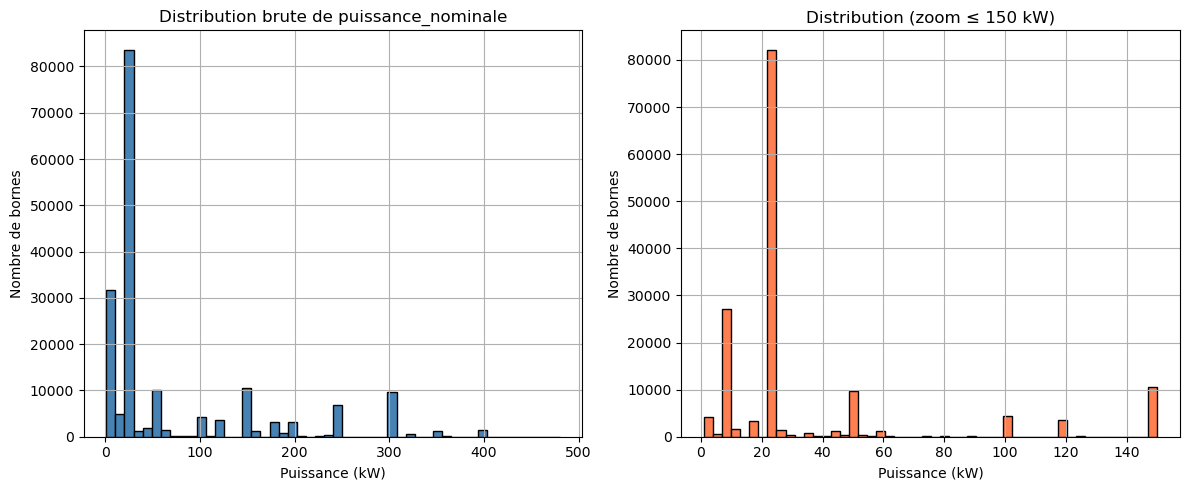

In [3]:
# Vérification de valeurs suspectes et visualisation de la distribution
print(f"Bornes avec puissance = 0 : {(df['puissance_nominale'] == 0).sum()}")
print(f"Bornes avec puissance < 3 : {(df['puissance_nominale'] < 3).sum()}")

# Histogrammes : distribution globale et zoom ≤ 150 kW
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
df['puissance_nominale'].hist(bins=50, color='steelblue', edgecolor='black')
plt.title("Distribution brute de puissance_nominale")
plt.xlabel("Puissance (kW)")
plt.ylabel("Nombre de bornes")

plt.subplot(1, 2, 2)
df[df['puissance_nominale'] <= 150]['puissance_nominale'].hist(
    bins=50, color='coral', edgecolor='black')
plt.title("Distribution (zoom ≤ 150 kW)")
plt.xlabel("Puissance (kW)")
plt.ylabel("Nombre de bornes")

plt.tight_layout()
plt.savefig("distribution_puissance_nominale.png", dpi=150)
plt.show()

## 2 — Sélection des features + corrélation

In [4]:
from scipy import stats

# Sélection de features candidates pour analyse
features_candidates = [
    'implantation_station', 'consolidated_longitude', 'consolidated_latitude',
    'nbre_pdc', 'prise_type_ef', 'prise_type_2', 'prise_type_combo_ccs',
    'prise_type_chademo', 'prise_type_autre', 'gratuit', 'paiement_acte',
    'paiement_cb', 'paiement_autre', 'reservation', 'station_deux_roues',
    'condition_acces', 'accessibilite_pmr'
]

df_model = df[features_candidates + ['puissance_nominale']].copy()

# Colonnes numériques/binaires retenues pour correlation
numeric_cols_for_corr = [
    'nbre_pdc', 'prise_type_ef', 'prise_type_2', 'prise_type_combo_ccs',
    'prise_type_chademo', 'prise_type_autre', 'gratuit', 'paiement_acte',
    'paiement_cb', 'paiement_autre', 'reservation', 'station_deux_roues',
    'consolidated_longitude', 'consolidated_latitude'
]


df_temp = df_model.copy() #on crée une copie indépendante du dataset pour éviter les modifications non intentionnelles sur df_model

# Calcul Spearman entre chaque feature numérique et la cible qui est toujours puissance_nominale (au cas ou la corrélation n'est pas linéaire)
correlations = {}
for col in numeric_cols_for_corr:
    clean = df_temp[[col, 'puissance_nominale']].dropna()
    corr, pval = stats.spearmanr(clean[col], clean['puissance_nominale'])
    correlations[col] = {'correlation': round(corr, 4), 'p_value': round(pval, 6)}

corr_df = pd.DataFrame(correlations).T.sort_values('correlation', key=abs, ascending=False)
print("Corrélation de Spearman avec puissance_nominale :")
print(corr_df)

Corrélation de Spearman avec puissance_nominale :
                        correlation  p_value
prise_type_combo_ccs         0.7772      0.0
prise_type_2                -0.7178      0.0
prise_type_ef               -0.4164      0.0
paiement_cb                  0.2662      0.0
prise_type_chademo           0.1595      0.0
reservation                 -0.1519      0.0
paiement_acte                0.1451      0.0
paiement_autre               0.0791      0.0
prise_type_autre            -0.0752      0.0
consolidated_latitude       -0.0706      0.0
nbre_pdc                     0.0612      0.0
consolidated_longitude       0.0545      0.0
station_deux_roues           0.0425      0.0
gratuit                     -0.0195      0.0


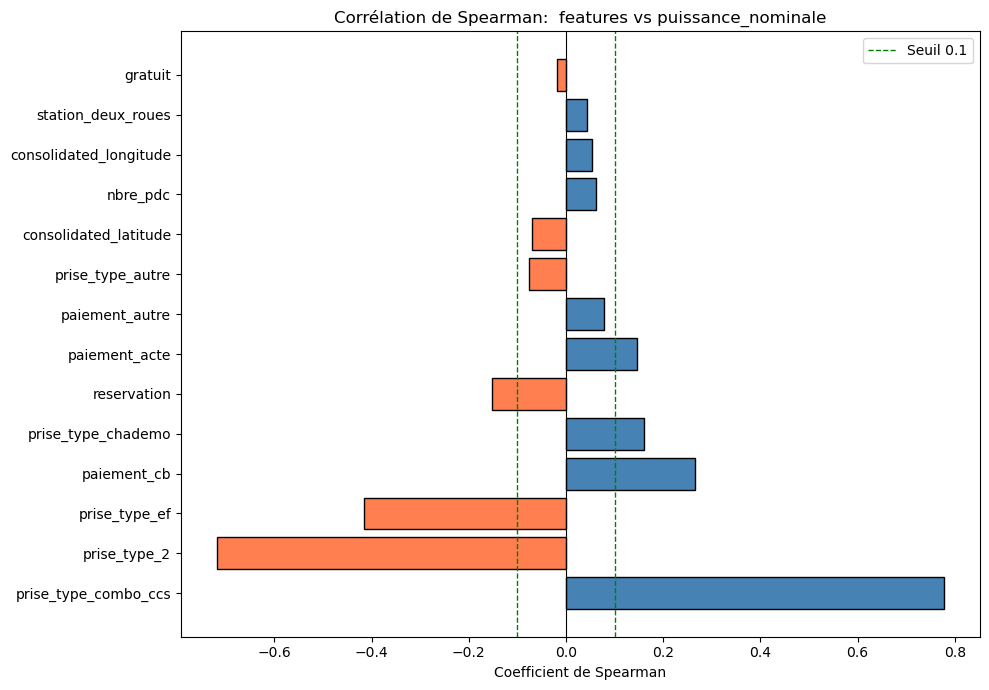

In [5]:
# Visualisation des corrélations
plt.figure(figsize=(10, 7))
colors = ['coral' if v < 0 else 'steelblue' for v in corr_df['correlation']]
plt.barh(corr_df.index, corr_df['correlation'], color=colors, edgecolor='black')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.axvline(x=0.1, color='green', linewidth=1, linestyle='--', label='Seuil 0.1')
plt.axvline(x=-0.1, color='green', linewidth=1, linestyle='--')
plt.title("Corrélation de Spearman:  features vs puissance_nominale", fontsize=12)
plt.xlabel("Coefficient de Spearman")
plt.legend()
plt.tight_layout()
plt.savefig("correlation_spearman.png", dpi=150)
plt.show()

## 3 - Sélectionner les variables finales

In [6]:
# Choix des features finales (manuellement retenues après analyse sup à 0.1 ou inf à -0.1)
features_finales = [
    'prise_type_combo_ccs',
    'prise_type_2',
    'prise_type_ef',
    'prise_type_chademo',
    'reservation',
    'paiement_acte',
    'implantation_station',
    'condition_acces',
    'accessibilite_pmr'
]

df_clean = df_model[features_finales + ['puissance_nominale']].dropna().copy() # on retire les lignes avec NaN dans les features finales ou la cible et on crée une copie indépendante du dataset

print(f"Dataset final : {df_clean.shape[0]:,} lignes x {df_clean.shape[1]} colonnes") 
print(f"\nVérification NaN :")
print(df_clean.isnull().sum())


Dataset final : 181,599 lignes x 10 colonnes

Vérification NaN :
prise_type_combo_ccs    0
prise_type_2            0
prise_type_ef           0
prise_type_chademo      0
reservation             0
paiement_acte           0
implantation_station    0
condition_acces         0
accessibilite_pmr       0
puissance_nominale      0
dtype: int64


## 4 - Nettoyage et encodage

In [7]:
import unicodedata
from sklearn.preprocessing import OneHotEncoder
import joblib
import pandas as pd

# Nettoyage texte + encodage one-hot des catégories
def clean_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', str(text))
    text = text.encode('ascii', 'ignore').decode('ascii')
    return text.strip()

# Appliquer nettoyage aux colonnes catégorielles sélectionnées
for col in ['implantation_station', 'condition_acces', 'accessibilite_pmr']:
    df_clean = df.copy()
    df_clean = df_clean.dropna().copy()   
    df_clean[col] = df_clean[col].apply(clean_text)

# Corrections de typos/mappings fréquents
mapping_implantation = {
    'Parking priv  usage public': 'Parking prive a usage public',
    'Parking priv rserv  la clientle': 'Parking prive reserve a la clientele',
}
mapping_condition = {
    'Accs libre': 'Acces libre',
    'Acc s libre': 'Acces libre',
    'AccA s libre': 'Acces libre',
}
mapping_accessibilite = {
    'Accessibilit inconnue': 'Accessibilite inconnue',
    'AccessibilitA inconnue': 'Accessibilite inconnue',
}

# modification des valeurs dans le DataFrame en utilisant les mappings définis juste au dessus
df_clean['implantation_station'] = df_clean['implantation_station'].replace(mapping_implantation)
df_clean['condition_acces'] = df_clean['condition_acces'].replace(mapping_condition)
df_clean['accessibilite_pmr'] = df_clean['accessibilite_pmr'].replace(mapping_accessibilite)


cat_cols = ['implantation_station', 'condition_acces', 'accessibilite_pmr']

# Fit OneHotEncoder (ignore les modalités inconnues en prédiction)
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(df_clean[cat_cols])

# Transformation en DataFrame one-hot et remplacement des colonnes
X_cat_ohe = ohe.transform(df_clean[cat_cols])
ohe_feature_names = ohe.get_feature_names_out(cat_cols)
df_ohe = pd.DataFrame(X_cat_ohe, columns=ohe_feature_names, index=df_clean.index)
df_clean = df_clean.drop(columns=cat_cols).join(df_ohe)

# Sauvegarde de l'encodeur pour usage futur
joblib.dump(ohe, "onehot_encoder.pkl")
print("OneHotEncoder sauvegardé (onehot_encoder.pkl)")
print("\nNb colonnes one-hot:", len(ohe_feature_names))
print("Exemples de colonnes:", list(ohe_feature_names[:15]))

OneHotEncoder sauvegardé (onehot_encoder.pkl)

Nb colonnes one-hot: 15
Exemples de colonnes: ['implantation_station_Parking priv\x8e r\x8eserv\x8e \x88 la client\x8fle', 'implantation_station_Parking priv\x8e \x88 usage public', 'implantation_station_Parking privé réservé à la clientèle', 'implantation_station_Parking privé à usage public', 'implantation_station_Parking public', 'implantation_station_Station dédiée à la recharge rapide', 'implantation_station_Voirie', 'condition_acces_Acc\x8fs libre', 'condition_acces_Acc¸s libre', 'condition_acces_Accès libre', 'condition_acces_Accès réservé', 'accessibilite_pmr_Accessibilite inconnue', 'accessibilite_pmr_Accessible mais non reserve PMR', 'accessibilite_pmr_Non accessible', 'accessibilite_pmr_Reserve PMR']


### 4.2 Séparation des données pour entrainer le modèle (80/20)

In [8]:
from sklearn.model_selection import train_test_split

# découpage du dataset train/test 80/20
X = df_clean.drop(columns=['puissance_nominale'])
y = df_clean['puissance_nominale']

# on mélange aléatoirement les lignes puis les répartit selon le ratio demandé
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, #80/20
    random_state=42 #garantit la reproductibilité du split (même lignes dans train/test à chaque exécution
)

#affichage des shapes et distribution de la cible dans le train
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"\nDistribution de y_train :")
print(y_train.describe())

X_train : (114911, 29)
X_test  : (28728, 29)

Distribution de y_train :
count    114911.000000
mean         62.293601
std          82.800477
min           1.000000
25%          22.000000
50%          22.000000
75%          50.000000
max         480.000000
Name: puissance_nominale, dtype: float64


## 5. Modélisation et optimisation
 
### 5.1 Random Forest avec 100 arbres

In [9]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Hyperparamètres de base pour le Random Forest
rf_base = RandomForestRegressor(
    n_estimators=100,   # nombre d'arbres de décision dans la forêt
    random_state=42,    # graine fixe pour la reproductibilité
    n_jobs=-1           # utilise tous les cœurs CPU disponibles pour accélérer l'entraînement
)

 # apprentissage
print("Entraînement du modèle de base en cours...")
rf_base.fit(X_train, y_train) 
print("Entraînement terminé")

# Prédiction de la puissance nominale sur le jeu de test
y_pred_base = rf_base.predict(X_test)

# Calcul des métriques de performance en comparant les prédictions aux vraies valeurs
mae  = mean_absolute_error(y_test, y_pred_base) # erreur moyenne
rmse = np.sqrt(mean_squared_error(y_test, y_pred_base)) #RMSE : pénalise davantage les grosses erreurs
r2   = r2_score(y_test, y_pred_base) # proportion de la variance de la cible expliquée par le modèle, objectif :ce raprocher de 1

#Affichage des métriques
print("\n MÉTRIQUES : Modèle de base ")
print(f"MAE  (Erreur absolue moyenne)  : {mae:.2f} kW")
print(f"RMSE (Erreur quadratique moy.) : {rmse:.2f} kW")
print(f"R²   (Coefficient détermination) : {r2:.4f}")

Entraînement du modèle de base en cours...
Entraînement terminé

 MÉTRIQUES : Modèle de base 
MAE  (Erreur absolue moyenne)  : 6.20 kW
RMSE (Erreur quadratique moy.) : 21.41 kW
R²   (Coefficient détermination) : 0.9343


### 5.2 Optimisation des hyperparamètres

In [10]:
# GridSearch pour optimiser Random Forest
from sklearn.model_selection import GridSearchCV

# 2 x 2 x 2 = 8 combinaisons d'hyperparamètres au total
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, None],
    'min_samples_leaf': [2, 5],
}
rf = RandomForestRegressor(random_state=42, n_jobs=-1)


# GridSearchCV teste chaque combinaison d'hyperparamètres avec une validation croisée
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,           # validation croisée à 5 parties
    scoring='r2',   # coefficient de détermination R² déterminer pour comparer les modèles
    verbose=1,      # je sais pas (à remplir!!)
    n_jobs=-1       # utilise tous les cœurs CPU disponibles pour accélérer l'optimisation
)
# Au total : 8 combinaisons x 5 plis = 40 entraînements de modèles

print(f"GridSearchCV sur {X_train.shape[0]:,} lignes...")
grid_search.fit(X_train, y_train) # recherche 

#affichage des résultats
print(f"\nMeilleurs paramètres : {grid_search.best_params_}")
print(f"Meilleur R² (CV) : {grid_search.best_score_:.4f}")

GridSearchCV sur 114,911 lignes...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Meilleurs paramètres : {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
Meilleur R² (CV) : 0.9210


## 6. Modèles alternatifs à Random Forest

### 6.1 — Régression Ridge (régression linéaire régularisée)

In [11]:
# Régression Ridge (pipeline : standardisation + Ridge)
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# on standardise les données puis on applique une régression Ridge
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()), # met toutes les variables à la même échelle
    ('ridge', Ridge(alpha=1.0)) # régression linéaire
])

# Entraînement sur les données d'entraînement
ridge_pipeline.fit(X_train, y_train)
# Prédictions sur le jeu de test
y_pred_ridge = ridge_pipeline.predict(X_test)

# Calcul des métriques de performance
mae_r  = mean_absolute_error(y_test, y_pred_ridge)
rmse_r = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_r   = r2_score(y_test, y_pred_ridge)

#affichage des métriques
print("métrique de performance — Ridge Regression")
print(f"MAE  : {mae_r:.2f} kW")
print(f"RMSE : {rmse_r:.2f} kW")
print(f"R²   : {r2_r:.4f}")

métrique de performance — Ridge Regression
MAE  : 31.35 kW
RMSE : 50.62 kW
R²   : 0.6323


In [12]:
# Régression Ridge — Optimisation par GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Même pipeline que ton modèle de base : normalisation + Ridge
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge',  Ridge())
])

# Grille de recherche sur le paramètre de régularisation alpha
param_grid = {
    'ridge__alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

grid_ridge = GridSearchCV(
    ridge_pipeline,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_ridge.fit(X_train, y_train)

# Meilleur modèle trouvé
print("Meilleurs paramètres :", grid_ridge.best_params_)
print(f"Meilleur R² (CV)     : {grid_ridge.best_score_:.4f}")

# Évaluation du meilleur modèle sur le test set (mêmes métriques que ton code)
best_ridge = grid_ridge.best_estimator_
y_pred_ridge = best_ridge.predict(X_test)

mae_r  = mean_absolute_error(y_test, y_pred_ridge)
rmse_r = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_r   = r2_score(y_test, y_pred_ridge)

print("\nMÉTRIQUES — Ridge Regression (optimisée)")
print(f"MAE  : {mae_r:.2f} kW")
print(f"RMSE : {rmse_r:.2f} kW")
print(f"R²   : {r2_r:.4f}")

Meilleurs paramètres : {'ridge__alpha': 10}
Meilleur R² (CV)     : 0.6407

MÉTRIQUES — Ridge Regression (optimisée)
MAE  : 31.35 kW
RMSE : 50.62 kW
R²   : 0.6323



COMPARAISON DES MODÈLES
                              MAE     RMSE      R²
Random Forest (base)       6.2005  21.4053  0.9343
Random Forest (optimisé)   7.0824  22.3515  0.9283
Ridge Regression          31.3505  50.6199  0.6323


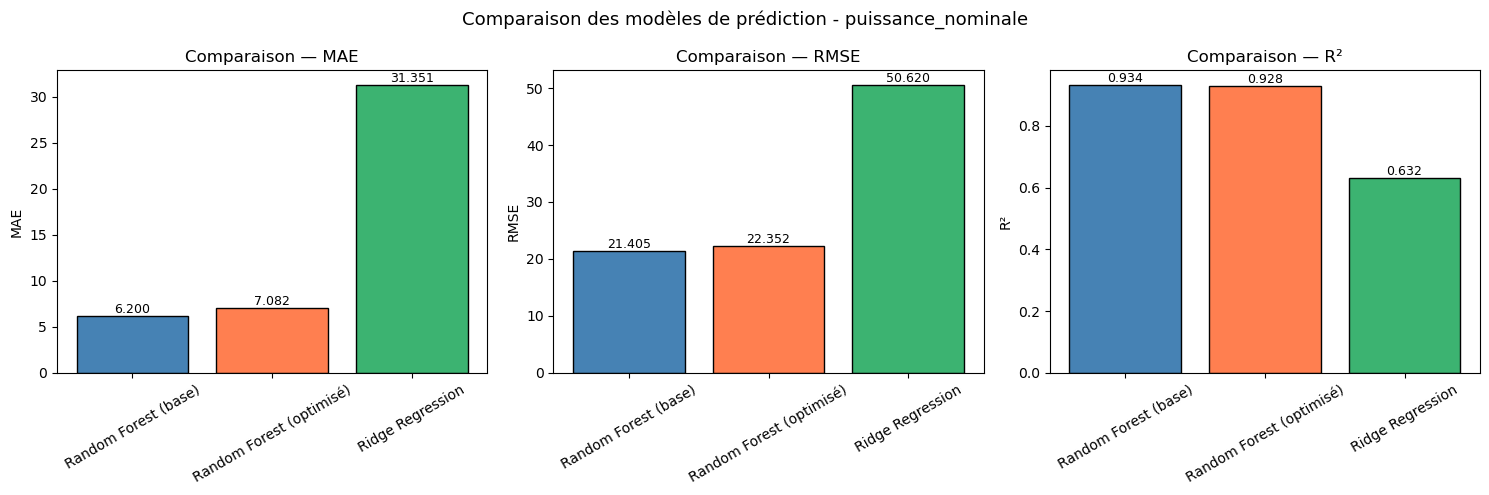

In [13]:
# Récupération des métriques Random Forest optimisé (depuis grid_search)
best_rf = grid_search.best_estimator_
# Prédictions sur le jeu de test avec ce modèle optimisé
y_pred_rf_opt = best_rf.predict(X_test)


# regroupe les métriques de tous les modèles pour pouvoir les comparérs
results = {
    'Random Forest (base)': {
        'MAE': mean_absolute_error(y_test, y_pred_base),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_base)),
        'R²': r2_score(y_test, y_pred_base)
    },
    'Random Forest (optimisé)': {
        'MAE': mean_absolute_error(y_test, y_pred_rf_opt),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_rf_opt)),
        'R²': r2_score(y_test, y_pred_rf_opt)
    },
    'Ridge Regression': {
        'MAE': mae_r,
        'RMSE': rmse_r,
        'R²': r2_r
    },
}

# Mise en forme des résultats dans un tableau 
df_results = pd.DataFrame(results).T.round(4)
print("\nCOMPARAISON DES MODÈLES")
print(df_results.to_string())

# Visualisation comparative des métriques en bar charts 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ['MAE', 'RMSE', 'R²']
colors  = ['steelblue', 'coral', 'mediumseagreen', 'mediumpurple']

for ax, metric in zip(axes, metrics):
    ax.bar(df_results.index, df_results[metric], color=colors, edgecolor='black')
    ax.set_title(f'Comparaison — {metric}')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=30)
    for i, v in enumerate(df_results[metric]):
        ax.text(i, v + 0.01 * max(df_results[metric]), f'{v:.3f}',
                ha='center', fontsize=9)

plt.suptitle("Comparaison des modèles de prédiction - puissance_nominale", fontsize=13)
plt.tight_layout()
plt.savefig("comparaison_modeles.png", dpi=150)
plt.show()

In [14]:
import joblib

# Sauvegarde du modèle Random Forest optimisé
joblib.dump(grid_search.best_estimator_, "random_forest_model.pkl")
print("Modèle RF sauvegardé")

# Sauvegarde de la liste des colonnes
joblib.dump(list(X_train.columns), "feature_columns.pkl")
print("Colonnes sauvegardées")

# Le OneHotEncoder est déjà sauvegardé en section 4

Modèle RF sauvegardé
Colonnes sauvegardées


Exception ignored in: <function ResourceTracker.__del__ at 0x10323dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x102ef1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106f19bc0>
Traceback (most recent call last